# Ранжирование объявлений в поиске

**Задача.** Для каждого запроса (`query_id`) отсортировать объявления по убыванию релевантности. Релевантность — `item_contact` (был ли контакт с продавцом), метрика — NDCG@10.

**Решение.** LightGBM `lambdarank` на табличных, текстовых и исторических признаках; 5-фолдовый ансамбль; дополнительное обучение на длинных «псевдо-выдачах», похожих на test.

| Раздел | Содержание |
|---|---|
| 1. Окружение и данные | установка, загрузка без текстов описаний |
| 2. EDA | таргет и группы, порядок строк (утечка), признаки, train vs test, качество данных, выводы |
| 3. Подготовка данных | очистка, фолды, метрика, признаки по разбиениям |
| 4. Baseline | сортировка по `click_conv`, LightGBM на табличных признаках |
| 5. Признаки | TF-IDF, BM25, эмбеддинги, target encoding, точечные признаки, cross-encoder (эксперимент) |
| 6. Итоговая модель | вклад признаков, 5-фолдовая валидация |
| 7. Длинные выдачи | обучение и валидация на выдачах, похожих на test |
| 8. Валидация и сабмит | сводная таблица NDCG@10, `solution.csv` |

**Запуск.** Положить `train-dset.parquet` и `test-dset-small.parquet` в корень Google Drive → Runtime → Change runtime type → **T4 GPU** → Run all. Результат — `solution.csv` в корне Drive. Эмбеддинги и оценки cross-encoder кешируются на Drive, поэтому повторный запуск быстрее. Без GPU ноутбук тоже отработает, но без эксперимента с cross-encoder — на итоговую модель это не влияет.

## 1. Окружение и данные

In [3]:
# версии зафиксированы (тот же список — в requirements.txt); torch и остальное, кроме polars и lightgbm, уже стоят в Colab
!pip install -q --extra-index-url https://download.pytorch.org/whl/cu130 \
    polars==2.1.0 lightgbm==4.6.0 torch==2.11.0+cu130 transformers==5.20.2 sentence-transformers==5.7.0 \
    scikit-learn==1.6.1 numpy==2.1.3 pandas==2.2.3 pyarrow==23.0.1 matplotlib==3.10.0 seaborn==0.13.2

In [4]:
import gc
import hashlib
import math
import os
import shutil

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import pyarrow.compute as pc
import pyarrow.parquet as pq
import seaborn as sns
import sentence_transformers
import sklearn
import torch
import torch.nn.functional as F
import transformers
from google.colab import drive
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup, set_seed

drive.mount('/content/drive')

DRIVE = '/content/drive/MyDrive'   # исходные данные, кеши и сабмиты
DATA_DIR = '/content'              # локальная копия данных: читается быстрее, чем с Drive
SEED = 42
TARGET = 'item_contact'
N_FOLDS = 5
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
set_seed(SEED)  # random, numpy, torch на CPU и GPU
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

sns.set_theme(style='whitegrid')
print(', '.join(f'{m.__name__} {m.__version__}' for m in (pl, lgb, np, torch, transformers, sentence_transformers, sklearn)),
      f'device: {DEVICE}', sep='; ')

Mounted at /content/drive
polars 2.1.0, lightgbm 4.6.0, device: cpu


Текст описаний (`item_description`) занимает ~6.4 из ~7.5 ГБ train и не помещается в память Colab вместе с остальными данными. Загружаем все колонки, кроме него, а от описания оставляем только длину — она считается по одной row group за раз.

In [5]:
def load_dataset(name: str) -> pl.DataFrame:
    path = f'{DATA_DIR}/{name}'
    if not os.path.exists(path):
        shutil.copy(f'{DRIVE}/{name}', path)
    pf = pq.ParquetFile(path)
    d = pl.read_parquet(path, columns=[c for c in pf.schema_arrow.names if c != 'item_description'])
    desc_len = np.concatenate([
        pc.fill_null(pc.utf8_length(pf.read_row_group(i, columns=['item_description']).column(0)), 0).to_numpy()
        for i in range(pf.num_row_groups)
    ])
    return d.with_columns(desc_len=pl.Series(desc_len, dtype=pl.Int32))


df = load_dataset('train-dset.parquet')
test = load_dataset('test-dset-small.parquet')
print(f'train: {df.shape}, {df.estimated_size() / 1e9:.2f} GB in memory; test: {test.shape}')
df.head()

train: (7781790, 14), 1.07 GB in memory; test: (335348, 13)


query_id,item_id,query_text,item_title,query_cat,query_mcat,query_loc,item_cat_id,item_mcat_id,item_loc,price,item_query_click_conv,item_contact,desc_len
i64,i64,str,str,f32,f64,f32,i32,i32,i32,f32,f32,f32,i32
4,7349717282,"""ботинки детские zara 21""","""Ботинки детские Zara""",29.0,38.0,624480.0,29,2179540,638660,500.0,-1.0,0.0,138
4,7519735286,"""ботинки детские zara 21""","""Детские ботинки Zara унисекс""",29.0,38.0,624480.0,29,2179540,637640,250.0,-1.0,0.0,36
4,4384449104,"""ботинки детские zara 21""","""Ботинки детские zara""",29.0,38.0,624480.0,29,2179540,623880,1500.0,-1.0,0.0,66
4,7283365509,"""ботинки детские zara 21""","""Детские ботиночки Zara 21 разм…",29.0,38.0,624480.0,29,2179540,628530,220.0,-1.0,0.0,26
4,4452768560,"""ботинки детские zara 21""","""Детские ботиночки zara размер …",29.0,38.0,624480.0,29,2179540,637640,1648.0,-1.0,1.0,121


## 2. EDA

Цель — понять структуру выдач, качество таргета и какие сигналы (конверсия, цена, категории, регион, текст) связаны с контактом. Выводы, влияющие на модель, собраны в конце раздела.

### 2.1 Обзор: типы, пропуски, уникальность

In [6]:
print(f'duplicated (query_id, item_id): {df.height - df.select(["query_id", "item_id"]).n_unique()}')
print(f'queries: {df["query_id"].n_unique():,}, items: {df["item_id"].n_unique():,}')
pl.DataFrame({
    'column': df.columns,
    'dtype': [str(t) for t in df.dtypes],
    'null_share': [df[c].null_count() / df.height for c in df.columns],
    'n_unique': [df[c].n_unique() for c in df.columns],
})

duplicated (query_id, item_id): 0
queries: 678,190, items: 5,773,058


column,dtype,null_share,n_unique
str,str,f64,i64
"""query_id""","""Int64""",0.0,678190
"""item_id""","""Int64""",0.0,5773058
"""query_text""","""String""",0.0,296669
"""item_title""","""String""",0.000014,3498755
"""query_cat""","""Float32""",0.0,64
…,…,…,…
"""item_loc""","""Int32""",0.0,3912
"""price""","""Float32""",0.0,64448
"""item_query_click_conv""","""Float32""",0.0,557


### 2.2 Таргет и размер выдач

NDCG считается внутри выдачи (`query_id`). Выдачи без единого контакта не влияют ни на обучение lambdarank (нет пар для сравнения), ни на метрику.

positive rate: 0.0441
queries without positives: 0.643, with all positives: 0.0093


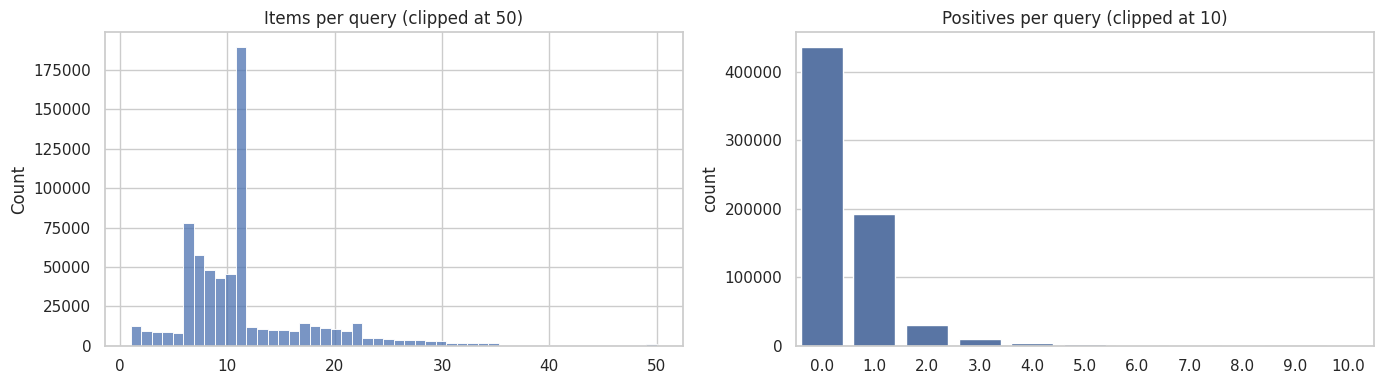

In [7]:
groups = df.group_by('query_id').agg(n_items=pl.len(), n_pos=pl.col(TARGET).sum())
print(f'positive rate: {df[TARGET].mean():.4f}')
print(f'queries without positives: {(groups["n_pos"] == 0).mean():.3f}, '
      f'with all positives: {(groups["n_pos"] == groups["n_items"]).mean():.4f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(groups['n_items'].clip(upper_bound=50).to_numpy(), bins=50, ax=axes[0])
axes[0].set_title('Items per query (clipped at 50)')
sns.countplot(x=groups['n_pos'].clip(upper_bound=10).to_numpy(), ax=axes[1], color='C0')
axes[1].set_title('Positives per query (clipped at 10)')
plt.tight_layout()
plt.show()

### 2.3 Порядок строк: train собран окнами вокруг контакта

Проверяем, несёт ли порядок строк в файле информацию о таргете. При случайном порядке доля контактов на всех позициях была бы около средней (~4.4%).

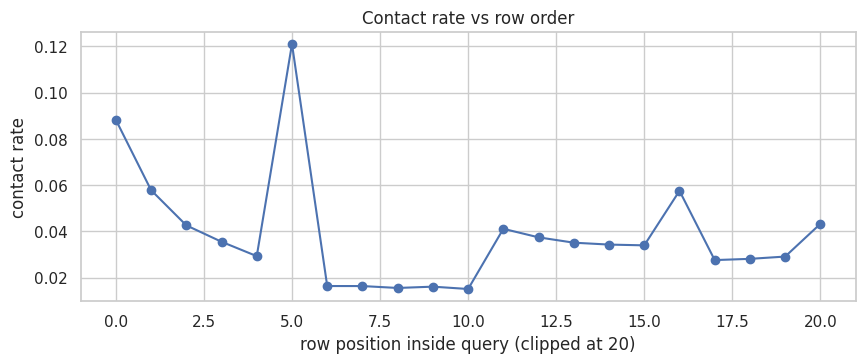

shape: (10, 4)
┌─────────┬───────────┬─────────┬──────────────────┐
│ n_items ┆ n_queries ┆ top_pos ┆ share_at_top_pos │
│ ---     ┆ ---       ┆ ---     ┆ ---              │
│ u32     ┆ u32       ┆ i64     ┆ f64              │
╞═════════╪═══════════╪═════════╪══════════════════╡
│ 11      ┆ 45675     ┆ 5       ┆ 0.968867         │
│ 6       ┆ 27439     ┆ 0       ┆ 0.861365         │
│ 7       ┆ 18406     ┆ 1       ┆ 0.791698         │
│ 8       ┆ 14308     ┆ 2       ┆ 0.716452         │
│ 10      ┆ 12634     ┆ 4       ┆ 0.543138         │
│ 9       ┆ 12255     ┆ 3       ┆ 0.684374         │
│ 1       ┆ 5888      ┆ 0       ┆ 1.0              │
│ 17      ┆ 4061      ┆ 11      ┆ 0.342034         │
│ 2       ┆ 3886      ┆ 0       ┆ 0.656716         │
│ 22      ┆ 3526      ┆ 5       ┆ 0.39308          │
└─────────┴───────────┴─────────┴──────────────────┘


In [8]:
pos_stats = (
    df.with_columns(row_pos=pl.int_range(pl.len()).over('query_id'))
    .group_by(pl.col('row_pos').clip(upper_bound=20))
    .agg(contact_rate=pl.col(TARGET).mean())
    .sort('row_pos')
)
plt.figure(figsize=(10, 3.5))
plt.plot(pos_stats['row_pos'], pos_stats['contact_rate'], marker='o')
plt.xlabel('row position inside query (clipped at 20)')
plt.ylabel('contact rate')
plt.title('Contact rate vs row order')
plt.show()

# где стоит контакт в выдачах ровно с одним контактом — по размеру выдачи
print(
    df.with_columns(row_pos=pl.int_range(pl.len()).over('query_id'), n_items=pl.len().over('query_id'))
    .filter(pl.col(TARGET).sum().over('query_id') == 1, pl.col(TARGET) == 1)
    .group_by('n_items')
    .agg(n_queries=pl.len(),
         top_pos=pl.col('row_pos').mode().first(),
         share_at_top_pos=(pl.col('row_pos') == pl.col('row_pos').mode().first()).mean())
    .sort('n_queries', descending=True)
    .head(10)
)

**Вывод.** На позиции 5 — резкий пик доли контактов (~12%), на позициях 6–10 — провал (~1.6%). Таблица объясняет почему: в выдачах из 11 строк единственный контакт в ~97% случаев стоит ровно в середине. **Каждая выдача train — окно** из исходной выдачи: 5 объявлений сверху + объявление с контактом + 5 снизу; если контакт был близко к началу, окно обрезано сверху (7 строк → контакт на позиции 1, 10 строк → на позиции 4).

Следствия:
- позиция строки — **утечка таргета**: модель с ней получает NDCG@10 ≈ 0.79 на валидации, просто находя центр окна. В test выдачи целые (30–50 объявлений), и этот приём там не работает. Позицию как признак не используем;
- перемешиваем строки внутри каждого запроса, чтобы ни один следующий шаг не опирался на исходный порядок; запросы остаются непрерывными блоками (нужно для `group` в LightGBM);
- негативы в train — ближайшие соседи объявления с контактом, то есть «трудные» примеры; длинного нерелевантного хвоста, как в test, в train нет (к этому вернёмся в разделе 7).

In [9]:
df = (
    df.with_columns(_shuffle=pl.Series(np.random.default_rng(SEED).random(df.height)))
    .sort(['query_id', '_shuffle'])
    .drop('_shuffle')
)
# проверка: пик и провал исчезли. Лёгкий плавный спад остаётся из-за состава: позиция 0 есть у всех выдач,
# дальние позиции — только у длинных, где доля контактов на одно объявление ниже
print(
    df.with_columns(row_pos=pl.int_range(pl.len()).over('query_id'))
    .filter(pl.col('row_pos') <= 10)
    .group_by('row_pos').agg(contact_rate=pl.col(TARGET).mean())
    .sort('row_pos')
)

shape: (11, 2)
┌─────────┬──────────────┐
│ row_pos ┆ contact_rate │
│ ---     ┆ ---          │
│ i64     ┆ f32          │
╞═════════╪══════════════╡
│ 0       ┆ 0.056189     │
│ 1       ┆ 0.047987     │
│ 2       ┆ 0.04535      │
│ 3       ┆ 0.043907     │
│ 4       ┆ 0.042813     │
│ …       ┆ …            │
│ 6       ┆ 0.039453     │
│ 7       ┆ 0.037581     │
│ 8       ┆ 0.036517     │
│ 9       ┆ 0.035416     │
│ 10      ┆ 0.03362      │
└─────────┴──────────────┘


### 2.4 Конверсия `item_query_click_conv`

Значение `-1` — маркер «нет статистики» (объявление не показывалось по запросу), а не конверсия.

share of -1 (no stats): 0.845
queries where all items have conv = -1: 0.475


/tmp/ipykernel_2271/3186167420.py:8: DeprecationWarning: `cut` is deprecated; use `bin_intervals` instead
  .otherwise(conv.cut([0, 0.05, 0.1, 0.2, 0.4], left_closed=True).cast(pl.String)))


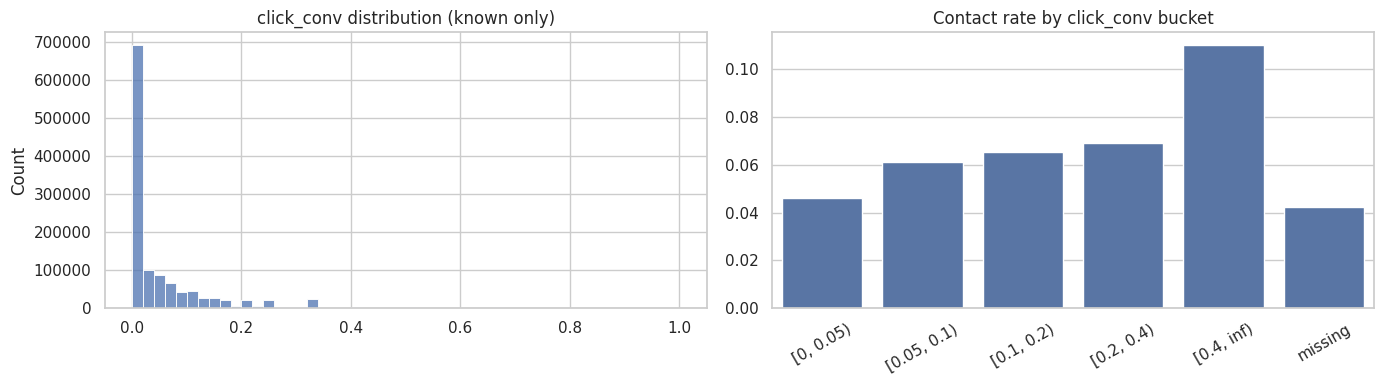

In [10]:
conv = pl.col('item_query_click_conv')
print(f'share of -1 (no stats): {(df["item_query_click_conv"] == -1).mean():.3f}')
conv_by_query = df.group_by('query_id').agg(n_known=(conv >= 0).sum(), n_items=pl.len())
print(f'queries where all items have conv = -1: {(conv_by_query["n_known"] == 0).mean():.3f}')

conv_bins = (
    df.with_columns(conv_bin=pl.when(conv < 0).then(pl.lit('missing'))
                    .otherwise(conv.cut([0, 0.05, 0.1, 0.2, 0.4], left_closed=True).cast(pl.String)))
    .group_by('conv_bin').agg(contact_rate=pl.col(TARGET).mean(), n=pl.len())
    .sort('conv_bin')
)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df.filter(conv >= 0)['item_query_click_conv'].to_numpy(), bins=50, ax=axes[0])
axes[0].set_title('click_conv distribution (known only)')
sns.barplot(x=conv_bins['conv_bin'].to_numpy(), y=conv_bins['contact_rate'].to_numpy(), ax=axes[1], color='C0')
axes[1].set_title('Contact rate by click_conv bucket')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

### 2.5 Цена

Абсолютная цена несравнима между категориями, поэтому смотрим и на относительную цену внутри выдачи.

  price == 0: share 0.0842, contact rate 0.0793
  price == 1: share 0.0043, contact rate 0.0733
 price > 1e8: share 0.0001, contact rate 0.0300
overall contact rate: 0.0441


/tmp/ipykernel_2271/320339435.py:8: DeprecationWarning: `cut` is deprecated; use `bin_intervals` instead
  .cut([0.2, 0.4, 0.6, 0.8]).cast(pl.String))


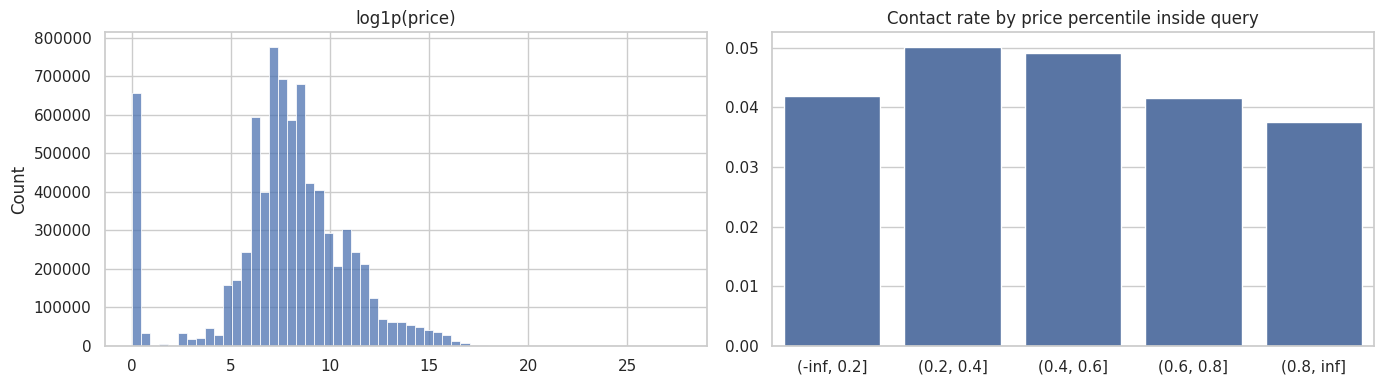

In [11]:
price = df['price']
for name, m in [('price == 0', price == 0), ('price == 1', price == 1), ('price > 1e8', price > 1e8)]:
    print(f'{name:>12}: share {m.mean():.4f}, contact rate {df.filter(m)[TARGET].mean():.4f}')
print(f'overall contact rate: {df[TARGET].mean():.4f}')

price_rel = (
    df.with_columns(bin=(pl.col('price').rank('average').over('query_id') / pl.len().over('query_id'))
                    .cut([0.2, 0.4, 0.6, 0.8]).cast(pl.String))
    .group_by('bin').agg(contact_rate=pl.col(TARGET).mean())
    .sort('bin')
)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(price.log1p().to_numpy(), bins=60, ax=axes[0])
axes[0].set_title('log1p(price)')
sns.barplot(x=price_rel['bin'].to_numpy(), y=price_rel['contact_rate'].to_numpy(), ax=axes[1], color='C0')
axes[1].set_title('Contact rate by price percentile inside query')
plt.tight_layout()
plt.show()

### 2.6 Категории и регион

Совпадение категории / региона запроса и объявления — естественный признак релевантности. `query_cat = 0` и `query_loc = 0` — «не определено» (см. 2.9), такие строки не считаем ни совпадением, ни промахом (null).

shape: (3, 3)
┌───────────┬──────────┬──────────────┐
│ cat_match ┆ share    ┆ contact_rate │
│ ---       ┆ ---      ┆ ---          │
│ bool      ┆ f64      ┆ f32          │
╞═══════════╪══════════╪══════════════╡
│ null      ┆ 0.224624 ┆ 0.043546     │
│ false     ┆ 0.077036 ┆ 0.031416     │
│ true      ┆ 0.69834  ┆ 0.045616     │
└───────────┴──────────┴──────────────┘
shape: (3, 3)
┌────────────┬──────────┬──────────────┐
│ mcat_match ┆ share    ┆ contact_rate │
│ ---        ┆ ---      ┆ ---          │
│ bool       ┆ f64      ┆ f32          │
╞════════════╪══════════╪══════════════╡
│ null       ┆ 0.226327 ┆ 0.043538     │
│ false      ┆ 0.470351 ┆ 0.039531     │
│ true       ┆ 0.303321 ┆ 0.051465     │
└────────────┴──────────┴──────────────┘
shape: (3, 3)
┌───────────┬──────────┬──────────────┐
│ loc_match ┆ share    ┆ contact_rate │
│ ---       ┆ ---      ┆ ---          │
│ bool      ┆ f64      ┆ f32          │
╞═══════════╪══════════╪══════════════╡
│ null      ┆ 0.164773 ┆ 0.04

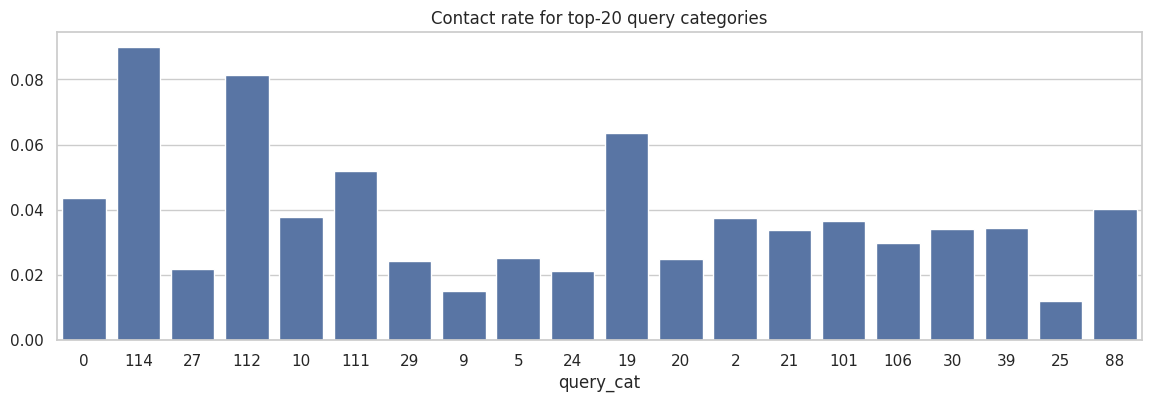

In [12]:
def known_match(q_col: str, i_col: str) -> pl.Expr:
    return pl.when(pl.col(q_col).is_null() | (pl.col(q_col) == 0)).then(None).otherwise(pl.col(q_col) == pl.col(i_col))


for name, expr in [('cat_match', known_match('query_cat', 'item_cat_id')),
                   ('mcat_match', known_match('query_mcat', 'item_mcat_id')),
                   ('loc_match', known_match('query_loc', 'item_loc'))]:
    print(df.group_by(expr.alias(name)).agg(share=pl.len() / df.height, contact_rate=pl.col(TARGET).mean()).sort(name))

top_cats = (
    df.group_by('query_cat').agg(n=pl.len(), contact_rate=pl.col(TARGET).mean())
    .sort('n', descending=True).head(20)
)
plt.figure(figsize=(14, 4))
sns.barplot(x=top_cats['query_cat'].cast(pl.Int64).cast(pl.String).to_numpy(),
            y=top_cats['contact_rate'].to_numpy(), color='C0')
plt.title('Contact rate for top-20 query categories')
plt.xlabel('query_cat')
plt.show()

### 2.7 Текст: запрос ↔ заголовок

Если пересечение слов запроса и заголовка связано с таргетом, TF-IDF / BM25 признаки должны дать прирост. Считаем на 50k запросов для скорости.

empty descriptions: 0.043
shape: (1, 1)
┌──────────────────────────────┐
│ spearman(q_coverage, target) │
│ ---                          │
│ f64                          │
╞══════════════════════════════╡
│ 0.022209                     │
└──────────────────────────────┘


/tmp/ipykernel_2271/2169915613.py:15: DeprecationWarning: `cut` is deprecated; use `bin_intervals` instead
  text_df.group_by(pl.col('q_coverage').cut([0.01, 0.34, 0.67, 0.99]).cast(pl.String).alias('bin'))


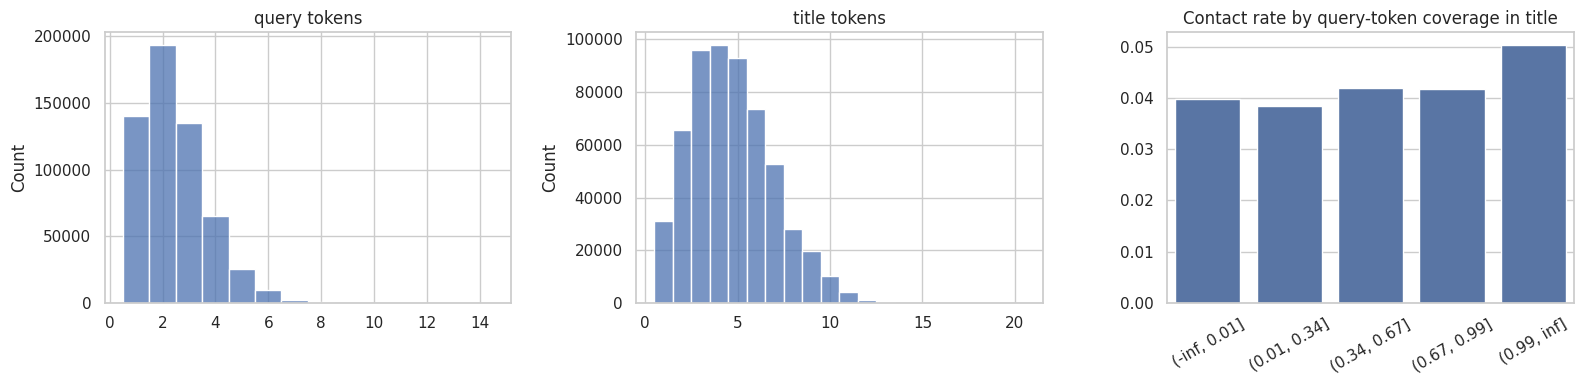

query_text,item_title,price,item_query_click_conv,item_contact
str,str,f32,f32,f32
"""снять коттедж с бассейном""","""5-к. коттедж, 350 м²""",13500.0,0.111,0.0
"""снять коттедж с бассейном""","""Баня с мангальной зоной, бесед…",1600.0,-1.0,0.0
"""снять коттедж с бассейном""","""Загородный дом с бассейном""",6000.0,-1.0,0.0
"""снять коттедж с бассейном""","""7-к. коттедж, 300 м²""",15000.0,-1.0,0.0
"""снять коттедж с бассейном""","""3-к. коттедж, 60 м²""",1000.0,-1.0,0.0
"""снять коттедж с бассейном""","""3-к. коттедж, 160 м²""",18000.0,-1.0,0.0
"""снять коттедж с бассейном""","""Загородный коттедж с бассейном""",25000.0,-1.0,0.0
"""снять коттедж с бассейном""","""2-к. коттедж, 90 м²""",5000.0,-1.0,0.0


In [13]:
sample_q = df['query_id'].unique().sample(50_000, seed=SEED)
text_df = (
    df.filter(pl.col('query_id').is_in(sample_q.implode()))
    .with_columns(q_tokens=pl.col('query_text').str.to_lowercase().str.extract_all(r'\w+').list.unique(),
                  t_tokens=pl.col('item_title').str.to_lowercase().str.extract_all(r'\w+').list.unique())
    .with_columns(q_len=pl.col('q_tokens').list.len(),
                  t_len=pl.col('t_tokens').list.len(),
                  inter=pl.col('q_tokens').list.set_intersection(pl.col('t_tokens')).list.len())
    .with_columns(q_coverage=pl.col('inter') / pl.col('q_len').clip(lower_bound=1))
)
print(f'empty descriptions: {(text_df["desc_len"] == 0).mean():.3f}')
print(text_df.select(pl.corr('q_coverage', TARGET, method='spearman').alias('spearman(q_coverage, target)')))

cov = (
    text_df.group_by(pl.col('q_coverage').cut([0.01, 0.34, 0.67, 0.99]).cast(pl.String).alias('bin'))
    .agg(contact_rate=pl.col(TARGET).mean())
    .sort('bin')
)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(text_df['q_len'].clip(upper_bound=15).to_numpy(), discrete=True, ax=axes[0])
axes[0].set_title('query tokens')
sns.histplot(text_df['t_len'].clip(upper_bound=20).to_numpy(), discrete=True, ax=axes[1])
axes[1].set_title('title tokens')
sns.barplot(x=cov['bin'].to_numpy(), y=cov['contact_rate'].to_numpy(), ax=axes[2], color='C0')
axes[2].set_title('Contact rate by query-token coverage in title')
axes[2].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

text_df.filter(pl.col('query_id') == sample_q[0]).select(['query_text', 'item_title', 'price', 'item_query_click_conv', TARGET])

### 2.8 Train vs test

Определяет схему валидации: если запросы test не встречаются в train, валидироваться нужно разбиением по `query_id`, иначе оценка будет завышена.

In [14]:
print(f'test query_id seen in train:   {test["query_id"].is_in(df["query_id"].unique().implode()).mean():.3f}')
print(f'test items seen in train:      {test["item_id"].is_in(df["item_id"].unique().implode()).mean():.3f}')
q_train = df.unique('query_id').select(['query_id', 'query_text'])
q_test = test.unique('query_id').select(['query_id', 'query_text'])
print(f'test queries whose text occurs in train: {q_test["query_text"].is_in(q_train["query_text"].implode()).mean():.3f}')
print(f'train queries whose text occurs in another train query: {q_train["query_text"].is_duplicated().mean():.3f}')

sizes = pl.concat([
    df.group_by('query_id').len().with_columns(split=pl.lit('train')),
    test.group_by('query_id').len().with_columns(split=pl.lit('test')),
])
print('items per query:')
print(sizes.group_by('split').agg(pl.col('len').quantile(q).alias(f'q{int(q * 100)}') for q in [0.25, 0.5, 0.75, 0.95]))

test query_id seen in train:   0.000
test items seen in train:      0.353
test queries whose text occurs in train: 0.665
train queries whose text occurs in another train query: 0.653
items per query:
shape: (2, 5)
┌───────┬──────┬──────┬──────┬──────┐
│ split ┆ q25  ┆ q50  ┆ q75  ┆ q95  │
│ ---   ┆ ---  ┆ ---  ┆ ---  ┆ ---  │
│ str   ┆ f64  ┆ f64  ┆ f64  ┆ f64  │
╞═══════╪══════╪══════╪══════╪══════╡
│ train ┆ 7.0  ┆ 11.0 ┆ 11.0 ┆ 25.0 │
│ test  ┆ 17.0 ┆ 34.0 ┆ 34.0 ┆ 35.0 │
└───────┴──────┴──────┴──────┴──────┘


### 2.9 Качество данных

Маркеры «не определено», заглушки, согласованность полей запроса, дубли и шум в разметке.

In [15]:
# поля запроса должны совпадать у всех строк одного query_id
for c in ['query_text', 'query_cat', 'query_mcat', 'query_loc']:
    inconsistent = (df.group_by('query_id').agg(pl.col(c).n_unique())[c] > 1).mean()
    print(f'{c:>11}: share of queries with >1 value = {inconsistent:.4f}')

# нули в идентификаторах — кандидаты в «не определено»
for c in ['query_cat', 'query_loc', 'item_cat_id', 'item_mcat_id']:
    m = df[c] == 0
    print(f'{c:>12} == 0: share {m.mean():.4f}, contact rate {df.filter(m)[TARGET].mean():.4f}')

# копии объявлений: одинаковый заголовок внутри одной выдачи (на подвыборке из 2.7)
dup_titles = text_df.select(pl.struct('query_id', pl.col('item_title').str.to_lowercase()).is_duplicated().mean()).item()
print(f'rows whose title repeats inside the same query: {dup_titles:.3f}')

# шум в разметке: одна и та же пара (текст запроса, item) в разных выдачах с разным таргетом
pairs = df.group_by(['query_text', 'item_id']).agg(n=pl.len(), rate=pl.col(TARGET).mean()).filter(pl.col('n') > 1)
print(f'rows in repeated (query_text, item) pairs: {pairs["n"].sum() / df.height:.3f}')
print(f'repeated pairs with conflicting target: {((pairs["rate"] > 0) & (pairs["rate"] < 1)).mean():.3f}')

 query_text: share of queries with >1 value = 0.0000
  query_cat: share of queries with >1 value = 0.0007
 query_mcat: share of queries with >1 value = 0.0008
  query_loc: share of queries with >1 value = 0.0003
   query_cat == 0: share 0.2246, contact rate 0.0435
   query_loc == 0: share 0.1648, contact rate 0.0434
 item_cat_id == 0: share 0.0032, contact rate 0.0718
item_mcat_id == 0: share 0.0030, contact rate 0.0712
rows whose title repeats inside the same query: 0.209
rows in repeated (query_text, item) pairs: 0.158
repeated pairs with conflicting target: 0.128


### Выводы EDA

Цифры — по полному train.

| Наблюдение | Решение |
|---|---|
| ~4.4% позитивов; у ~64% запросов нет контактов, у ~1% контакт у всех | выдачи без контактов не дают градиента lambdarank и не входят в NDCG → убираем; выдачи «контакт у всех» тоже не дают градиента → не обучаемся на них, но оставляем в метрике (NDCG = 1) |
| train — окна вокруг контакта, позиция строки — утечка | позицию не используем, строки внутри запроса перемешаны |
| медиана выдачи: train 11, test 34; в train нет «хвоста» выдачи | только относительные признаки (ранги/доли внутри выдачи); обучение на длинных псевдо-выдачах (раздел 7) |
| `click_conv = -1` у ~85% строк — пропуск | `conv` = NaN + флаг `conv_missing` |
| `query_cat = 0` (~22%), `query_loc = 0` (~16%) — «не определено» | null; признаки совпадения для них тоже null, а не 0 |
| цена 0 у ~8% строк с contact rate ~7.9% (вакансии, услуги, «договорная»), выбросы до 1e12 | флаг `price_missing`, `log1p`, цена относительно выдачи |
| совпадение региона заметно поднимает долю контактов, подкатегории — слабее | признаки совпадения + target encoding пар (категория / регион запроса, объявления) |
| пересечение слов запроса и заголовка слабо, но монотонно связано с контактом; много артикулов и латиницы | TF-IDF по словам и по символьным n-граммам, BM25, эмбеддинги |
| ~14% строк — копии заголовков внутри выдачи; ~13% повторяющихся пар (запрос, объявление) с разным таргетом | шум ограничивает потолок NDCG; признак `title_dups`, история по заголовку |
| запросы test не встречаются в train, но ~66% их текстов и ~35% объявлений есть в train | фолды по `query_id`; история по тексту запроса и объявлению — сильный легальный признак, на train только out-of-fold |

## 3. Подготовка данных

Одна функция `prepare()` применяется к train и test — признаки гарантированно считаются одним кодом.

| Проблема из EDA | Обработка |
|---|---|
| `click_conv = -1` | `conv` = NaN + флаг `conv_missing`, `conv_rank` — ранг внутри выдачи |
| `query_cat / query_loc = 0` | null; `cat_match`, `mcat_match`, `loc_match` для них null |
| цена 0 / 1 / > 1e8 | `price_missing`, `log_price`; `price_rank` и `price_vs_median` — относительно выдачи |
| регистр, «ё», пунктуация в текстах | нормализованные `query_norm`, `title_norm` для текстовых признаков |

Только для train: убираем выдачи без контактов, выдачи «контакт у всех» помечаем `trainable = False` — они остаются в валидации, но не в обучении. Запросы случайно распределяем по 5 фолдам.

In [ ]:
del groups, pos_stats, conv_by_query, conv_bins, price, price_rel, top_cats, cov, q_train, q_test, sizes, pairs
gc.collect()

PRICE_MAX = 1e8


def normalize_text(col: str) -> pl.Expr:
    """lower, ё → е, всё кроме букв и цифр → пробел."""
    return (pl.col(col).fill_null('').str.to_lowercase().str.replace_all('ё', 'е')
            .str.replace_all(r'[^\w]+', ' ').str.strip_chars())


def match(q_col: str, i_col: str) -> pl.Expr:
    return pl.when(pl.col(q_col).is_null()).then(None).otherwise(pl.col(q_col) == pl.col(i_col)).cast(pl.Int8)


def prepare(d: pl.DataFrame) -> pl.DataFrame:
    price_ok = (pl.col('price') > 1) & (pl.col('price') <= PRICE_MAX)
    return (
        d.with_columns(
            pl.col('query_cat').cast(pl.Int32).replace(0, None),
            pl.col('query_loc').cast(pl.Int32).replace(0, None),
            pl.col('query_mcat').cast(pl.Int32),
            conv=pl.when(pl.col('item_query_click_conv') >= 0).then(pl.col('item_query_click_conv')),
            conv_missing=(pl.col('item_query_click_conv') < 0).cast(pl.Int8),
            price_missing=(~price_ok).cast(pl.Int8),
            log_price=pl.when(price_ok).then(pl.col('price').log1p()),
            title_len=pl.col('item_title').fill_null('').str.len_chars(),
            query_norm=normalize_text('query_text'),
            title_norm=normalize_text('item_title'),
        )
        .with_columns(
            cat_match=match('query_cat', 'item_cat_id'),
            mcat_match=match('query_mcat', 'item_mcat_id'),
            loc_match=match('query_loc', 'item_loc'),
            price_rank=pl.col('log_price').rank('average').over('query_id') / pl.col('log_price').count().over('query_id'),
            price_vs_median=pl.col('log_price') - pl.col('log_price').median().over('query_id'),
            conv_rank=pl.col('conv').rank('average', descending=True).over('query_id') / pl.col('conv').count().over('query_id'),
        )
        .drop('item_query_click_conv')
    )


n_pos = pl.col(TARGET).sum().over('query_id')
# выдачи без контактов не влияют ни на обучение, ни на метрику — убираем. Выдачи, где контакт у всех,
# остаются в валидации (NDCG = 1), но не в обучении: у lambdarank нет пар для сравнения
train = prepare(df.filter(n_pos > 0).with_columns(trainable=n_pos < pl.len().over('query_id')))
test_prep = prepare(test)

# фолды по query_id: все строки запроса — в одном фолде
folds = pl.DataFrame({'query_id': train['query_id'].unique().sort()})
folds = folds.with_columns(fold=pl.Series(np.random.default_rng(SEED).integers(0, N_FOLDS, folds.height)))
# LightGBM требует, чтобы строки одного запроса шли подряд; maintain_order сохраняет перемешанный порядок внутри
train = train.join(folds, on='query_id', how='left').sort('query_id', maintain_order=True)
test_prep = test_prep.sort('query_id', maintain_order=True)

assert train.group_by('query_id').agg(pl.col('fold').n_unique())['fold'].max() == 1, 'query split across folds'
assert test_prep['query_id'].n_unique() == test['query_id'].n_unique(), 'test queries lost'
assert set(test_prep.columns) == set(train.columns) - {TARGET, 'fold', 'trainable'}, 'train/test columns differ'

print(f'train: {df.height:,} → {train.height:,} rows, {df["query_id"].n_unique():,} → {train["query_id"].n_unique():,} queries')
print(train.group_by('fold').agg(queries=pl.col('query_id').n_unique(), rows=pl.len(), pos_rate=pl.col(TARGET).mean(),
                                 all_pos_queries=pl.col('query_id').filter(~pl.col('trainable')).n_unique()).sort('fold'))

### Метрика и схема валидации

- **NDCG@10** считается одной функцией для всех моделей: среднее по запросам, где есть хотя бы один контакт, — включая выдачи, где контакт у всех (у них NDCG = 1). Ничьи в оценках разбиваются случайно — иначе результат зависел бы от порядка строк.
- **Фолд 0** — быстрые сравнения моделей и признаков (~1/5 запросов, которых модель не видела).
- **5 фолдов** — итоговая оценка: среднее ± разброс (раздел 6).
- **Признаки из таргета считаются заново для каждого разбиения.** Target encoding (5.2) и оценки cross-encoder (5.4) для разбиения `k` (обучение на фолдах ≠ `k`, валидация на `k`) используют только обучающую часть: ни одна обучающая строка не получает признак, посчитанный по таргетам фолда `k`. Поэтому в таблице `train` этих признаков нет — их добавляет `split_view(train, k)` перед обучением и оценкой.

Выдачи test в ~3 раза длиннее окон train, поэтому абсолютный NDCG на валидации не равен скору на test — сравниваем модели между собой.

In [ ]:
def ndcg_at_k(d: pl.DataFrame, score_col: str, k: int = 10) -> float:
    """Средний NDCG@k по запросам (`query_id`), у которых есть хотя бы один позитив."""
    d = (d.select(['query_id', score_col, TARGET])
         .with_columns(_tie=pl.Series(np.random.default_rng(SEED).random(d.height)))
         .filter(pl.col(TARGET).sum().over('query_id') > 0))

    def dcg(sort_cols):
        return (
            d.sort(['query_id', *sort_cols], descending=[False] + [True] * len(sort_cols))
            .with_columns(rank=pl.int_range(1, pl.len() + 1).over('query_id'))
            .filter(pl.col('rank') <= k)
            .group_by('query_id')
            .agg(dcg=(pl.col(TARGET) / (pl.col('rank') + 1).log(2)).sum())
        )

    res = dcg([score_col, '_tie']).join(dcg([TARGET]), on='query_id', suffix='_ideal')
    return (res['dcg'] / res['dcg_ideal']).mean()

## 4. Baseline

1. **Сортировка по `click_conv`** — без обучения; объявления без статистики ставим ниже любой известной конверсии.
2. **LightGBM `lambdarank`** на табличных признаках раздела 3. `group` — размеры выдач в порядке строк. Сырые id подкатегорий и регионов (тысячи–миллионы значений) в модель не идут: на них она переобучается, а их информация уже есть в признаках совпадения и в target encoding (раздел 5).

Все модели дальше обучаются функцией `fit_fold` с одними параметрами и early stopping по NDCG@10 на валидационном фолде — разница в метрике показывает вклад именно признаков.

In [ ]:
VALID_FOLD = 0
va = train.filter(pl.col('fold') == VALID_FOLD)
results = {  # журнал экспериментов: NDCG@10 на фолде 0
    'random': ndcg_at_k(va.with_columns(score=pl.lit(0)), 'score'),
    'click_conv sort': ndcg_at_k(va.with_columns(score=pl.col('conv').fill_null(-1)), 'score'),
}

TAB_FEATURES = [
    'conv', 'conv_missing', 'conv_rank',
    'log_price', 'price_missing', 'price_rank', 'price_vs_median',
    'cat_match', 'mcat_match', 'loc_match',
    'title_len', 'desc_len',
    'query_cat', 'item_cat_id',
]
CAT_IDS = ['query_cat', 'item_cat_id']  # десятки значений — LightGBM обрабатывает их как категории
LGB_PARAMS = {
    'objective': 'lambdarank',
    'metric': 'ndcg',
    'eval_at': [10],
    'learning_rate': 0.05,
    'num_leaves': 63,
    'min_data_in_leaf': 200,
    'feature_fraction': 0.8,
    'bagging_fraction': 0.8,
    'bagging_freq': 1,
    'lambda_l2': 1.0,
    'cat_smooth': 50,
    'seed': SEED,
    'verbose': -1,
}


def to_lgb(d: pl.DataFrame, features: list[str], reference=None) -> lgb.Dataset:
    """d отсортирован по query_id; group — размеры выдач в порядке следования строк."""
    return lgb.Dataset(
        d.select(features).to_pandas(),
        label=d[TARGET].cast(pl.Int32).to_numpy(),
        group=d.group_by('query_id', maintain_order=True).len()['len'].to_numpy(),
        categorical_feature=CAT_IDS,
        reference=reference,
        free_raw_data=False,
    )


def predict(model, d: pl.DataFrame, features: list[str]) -> np.ndarray:
    return model.predict(d.select(features).to_pandas(), num_iteration=model.best_iteration)


SPLIT_STEPS = []  # функции (d, k) -> d, добавляющие признаки из таргета для разбиения k (разделы 5.2, 5.4)


def split_view(d: pl.DataFrame, k: int) -> pl.DataFrame:
    """d с признаками из таргета, посчитанными только по обучающей части разбиения k (фолды != k)."""
    for step in SPLIT_STEPS:
        d = step(d, k)
    return d


def fit_fold(d: pl.DataFrame, features: list[str], k: int):
    """Обучает модель на всех фолдах, кроме k; возвращает модель и NDCG@10 на фолде k.
    Выдачи, где контакт у всех, в обучение не идут, но остаются в оценке."""
    d = split_view(d, k)
    tr, va = d.filter((pl.col('fold') != k) & pl.col('trainable')), d.filter(pl.col('fold') == k)
    dtr = to_lgb(tr, features)
    model = lgb.train(
        LGB_PARAMS, dtr, num_boost_round=3000,
        valid_sets=[to_lgb(va, features, reference=dtr)], valid_names=['valid'],
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    score = ndcg_at_k(va.select('query_id', TARGET).with_columns(score=pl.Series(predict(model, va, features))), 'score')
    return model, score


def plot_importance(models, features: list[str], title: str):
    gain = np.mean([m.feature_importance('gain') for m in models], axis=0)
    imp = pl.DataFrame({'feature': features, 'share': gain / gain.sum()}).sort('share', descending=True)
    plt.figure(figsize=(8, 0.25 * len(features) + 1))
    sns.barplot(x=imp['share'].to_numpy(), y=imp['feature'].to_numpy(), color='C0')
    plt.title(title)
    plt.show()


baseline_model, results['LightGBM: tabular'] = fit_fold(train, TAB_FEATURES, VALID_FOLD)
print(f'trees: {baseline_model.best_iteration}')
print(pl.DataFrame({'model': list(results), 'ndcg@10 (fold 0)': list(results.values())}))
plot_importance([baseline_model], TAB_FEATURES, 'Baseline LightGBM: feature importance (gain share)')

## 5. Признаки

Baseline видит только табличные признаки. Добавляем четыре группы:
1. **текстовая близость** запроса и заголовка (5.1);
2. **история** — target encoding объявлений, заголовков, категорий и регионов, отдельно для каждого разбиения (5.2);
3. **точечные** признаки: числа, артикулы, характеристики запроса и выдачи (5.3);
4. **cross-encoder** — нейросеть, дообученная на `item_contact` (5.4).

### 5.1 Текстовая близость запроса и заголовка

| Признак | Что ловит |
|---|---|
| `tfidf_word` | cosine TF-IDF по словам и биграммам: совпадение слов с учётом их редкости («zara» весит больше, чем «детские») |
| `tfidf_char` | cosine TF-IDF по символьным 3–5-граммам: словоформы («ботинки» ↔ «ботиночки»), опечатки, артикулы с дефисами |
| `bm25` | BM25 запроса по заголовку: повтор слова даёт прирост с насыщением, длинный заголовок штрафуется |
| `q_cover` | доля слов запроса, найденных в заголовке |
| `emb_cos` | cosine эмбеддингов `rubert-tiny2`: смысловая близость без общих слов («обувь для малыша» ↔ «детские ботинки») |
| `*_rank`, `*_gap` | место объявления в выдаче по признаку (доля, 0 = лучшее) и отставание от лучшего в выдаче |

Относительные версии нужны, потому что абсолютное сходство несравнимо между запросами: для запроса-артикула `tfidf_word = 0.3` может быть лучшим в выдаче, а для «ботинки zara» — худшим. Для сортировки важно, лучше ли объявление **соседей**.

Тяжёлые вычисления делаются по уникальным текстам (`q_idx`, `t_idx` — номера текста запроса и заголовка), затем раздаются по строкам. TF-IDF и BM25 обучаются на текстах train + test — таргет не используется, утечки нет.

In [ ]:
uniq_q = pl.concat([train['query_norm'], test_prep['query_norm']]).unique().sort()
uniq_t = pl.concat([train['title_norm'], test_prep['title_norm']]).unique().sort()
print(f'unique queries: {uniq_q.len():,}, unique titles: {uniq_t.len():,}')


def add_text_idx(d: pl.DataFrame) -> pl.DataFrame:
    return d.with_columns(
        q_idx=pl.col('query_norm').replace_strict(uniq_q, pl.int_range(uniq_q.len(), eager=True), return_dtype=pl.Int32),
        t_idx=pl.col('title_norm').replace_strict(uniq_t, pl.int_range(uniq_t.len(), eager=True), return_dtype=pl.Int32),
    )


train, test_prep = add_text_idx(train), add_text_idx(test_prep)


def rowwise_dot(A, B, a_idx: np.ndarray, b_idx: np.ndarray, chunk: int = 500_000) -> np.ndarray:
    """dot(A[a_idx[i]], B[b_idx[i]]) для каждой строки; по частям, чтобы не держать в памяти всю матрицу пар."""
    out = np.empty(len(a_idx), dtype=np.float32)
    for s in range(0, len(a_idx), chunk):
        out[s:s + chunk] = np.asarray(A[a_idx[s:s + chunk]].multiply(B[b_idx[s:s + chunk]]).sum(axis=1)).ravel()
    return out


def pair_feature(Q, T) -> tuple[np.ndarray, np.ndarray]:
    """Значения для (train, test) по матрицам уникальных запросов Q и заголовков T."""
    return tuple(rowwise_dot(Q, T, d['q_idx'].to_numpy(), d['t_idx'].to_numpy()) for d in (train, test_prep))


text_feats = {}  # имя → (значения train, значения test)
TOKEN = r'(?u)\b\w+\b'  # односимвольные токены тоже важны: размеры, категории прав «с», «е»
corpus = pl.concat([uniq_q, uniq_t]).to_list()

# TF-IDF: векторы L2-нормированы, поэтому dot = cosine
for name, params in [('tfidf_word', dict(token_pattern=TOKEN, ngram_range=(1, 2), min_df=2)),
                     ('tfidf_char', dict(analyzer='char_wb', ngram_range=(3, 5), min_df=3))]:
    vec = TfidfVectorizer(**params, max_features=500_000, sublinear_tf=True, dtype=np.float32).fit(corpus)
    text_feats[name] = pair_feature(vec.transform(uniq_q.to_list()), vec.transform(uniq_t.to_list()))
del vec, corpus

# BM25 (k1 — насыщение частоты слова, b — сила штрафа за длину; стандартные значения)
BM25_K1, BM25_B = 1.2, 0.75
cv = CountVectorizer(token_pattern=TOKEN, dtype=np.float32).fit(uniq_t.to_list())
C = cv.transform(uniq_t.to_list()).tocsr()           # частоты слов в заголовках
Qb = cv.transform(uniq_q.to_list()).tocsr()
Qb.data[:] = 1                                       # запрос — множество слов
doc_len = np.asarray(C.sum(axis=1)).ravel()
n_docs_with_term = np.bincount(C.indices, minlength=C.shape[1])
idf = np.log1p((C.shape[0] - n_docs_with_term + 0.5) / (n_docs_with_term + 0.5)).astype(np.float32)
W = C.copy()
row_len = np.repeat(doc_len / doc_len.mean(), np.diff(W.indptr))
W.data = idf[W.indices] * W.data * (BM25_K1 + 1) / (W.data + BM25_K1 * (1 - BM25_B + BM25_B * row_len))
text_feats['bm25'] = pair_feature(Qb, W)

# q_cover: число найденных слов запроса / число слов запроса
C.data[:] = 1
q_len = np.asarray(Qb.sum(axis=1)).ravel().clip(min=1)
text_feats['q_cover'] = tuple(hits / q_len[d['q_idx'].to_numpy()]
                              for hits, d in zip(pair_feature(Qb, C), (train, test_prep)))
del cv, C, Qb, W, row_len
gc.collect()

**Эмбеддинги.** `cointegrated/rubert-tiny2` — компактный (29M параметров) BERT для русского языка, обученный под близость предложений. Выбран за скорость: на T4 ~1.6M заголовков кодируются за несколько минут. Крупные модели (multilingual-e5) точнее, но в разы медленнее. Эмбеддинги кешируются на Drive.

In [ ]:
EMB_MODEL = 'cointegrated/rubert-tiny2'
EMB_CACHE = f'{DRIVE}/emb_rubert_tiny2.npz'


def encode(texts: list[str], model, batch: int = 100_000) -> np.ndarray:
    """L2-нормированные эмбеддинги в float16: вдвое меньше памяти, для cosine точности хватает."""
    out = np.empty((len(texts), model.get_sentence_embedding_dimension()), dtype=np.float16)
    for s in range(0, len(texts), batch):
        out[s:s + batch] = model.encode(texts[s:s + batch], batch_size=512, normalize_embeddings=True,
                                        convert_to_numpy=True, show_progress_bar=False)
    return out


cache = np.load(EMB_CACHE, allow_pickle=True) if os.path.exists(EMB_CACHE) else None
if cache is not None and cache['q_texts'].tolist() == uniq_q.to_list() and cache['t_texts'].tolist() == uniq_t.to_list():
    emb_q, emb_t = cache['emb_q'], cache['emb_t']
    print('embeddings loaded from cache')
else:
    print(f'encoding on {DEVICE}...')
    model = SentenceTransformer(EMB_MODEL, device=DEVICE)
    emb_q, emb_t = encode(uniq_q.to_list(), model), encode(uniq_t.to_list(), model)
    np.savez(EMB_CACHE, emb_q=emb_q, emb_t=emb_t,
             q_texts=np.array(uniq_q.to_list(), dtype=object), t_texts=np.array(uniq_t.to_list(), dtype=object))
    del model
del cache


def emb_cosine(d: pl.DataFrame, chunk: int = 1_000_000) -> np.ndarray:
    q_idx, t_idx = d['q_idx'].to_numpy(), d['t_idx'].to_numpy()
    out = np.empty(len(q_idx), dtype=np.float32)
    for s in range(0, len(q_idx), chunk):
        e = s + chunk
        out[s:e] = (emb_q[q_idx[s:e]].astype(np.float32) * emb_t[t_idx[s:e]].astype(np.float32)).sum(axis=1)
    return out


text_feats['emb_cos'] = (emb_cosine(train), emb_cosine(test_prep))
del emb_q, emb_t
gc.collect()

Добавляем 5 признаков и их `*_rank` / `*_gap` в таблицы. Spearman-корреляция с таргетом — быстрая проверка осмысленности: у признаков сходства она положительная, у `*_rank` и `*_gap` — отрицательная (там меньше = лучше).

In [ ]:
TEXT_BASE = list(text_feats)


def add_text_features(d: pl.DataFrame, part: int) -> pl.DataFrame:
    d = d.with_columns(pl.Series(name, vals[part]) for name, vals in text_feats.items())
    return d.with_columns(
        *[(pl.col(f).rank('average', descending=True).over('query_id') / pl.len().over('query_id')).alias(f'{f}_rank')
          for f in TEXT_BASE],
        *[(pl.col(f).max().over('query_id') - pl.col(f)).alias(f'{f}_gap') for f in TEXT_BASE],
    )


def spearman(d: pl.DataFrame, features: list[str]) -> pl.DataFrame:
    return (d.select([pl.corr(f, TARGET, method='spearman').alias(f) for f in features])
            .transpose(include_header=True, header_name='feature', column_names=['spearman'])
            .sort('spearman', descending=True))


train, test_prep = add_text_features(train, 0), add_text_features(test_prep, 1)
TEXT_FEATURES = [*TEXT_BASE, *[f'{f}_rank' for f in TEXT_BASE], *[f'{f}_gap' for f in TEXT_BASE]]
del text_feats
gc.collect()
spearman(train, TEXT_FEATURES)

### 5.2 История: target encoding по разбиениям

Модель не может напрямую использовать `item_id` или регион: значений сотни тысяч, и само число ничего не значит. Target encoding заменяет ключ на сглаженную долю контактов по нему в истории:

`te = (контакты + prior · m) / (показы + m)`, `m = 20`, `prior` — средняя доля контактов (~4.4%). Объявление с 1 показом и 1 контактом получит не 100%, а ≈ 9%. Рядом — `cnt_*` = log(показы + 1): насколько модели доверять `te`.

`prior` тоже считается только по обучающей части разбиения.

**Только по обучающей части разбиения.** История — весь train (7.8M строк, включая выдачи без контактов), запросы которого распределены по тем же 5 фолдам. Для разбиения `k`:
- строка обучающего фолда `f` получает статистику по фолдам, кроме `f` и `k`: без собственного таргета и без таргетов валидационного фолда;
- строка валидационного фолда `k` и test — по фолдам, кроме `k`: ровно то, что модель видела при обучении.

Признаки зависят от разбиения, поэтому считаются в `split_view(d, k)` перед каждым обучением и предсказанием, а не один раз для всей таблицы. Ключи заранее сворачиваются в один хеш (`h_*`), а история — в суммы по (ключ, фолд): так пересчёт для разбиения — несколько join'ов без повторной группировки 7.8M строк.

| Ключ | Вопрос, на который отвечает | |
|---|---|---|
| `item` | часто ли с объявлением связываются вообще (35% объявлений test есть в train) | базовые |
| `qtext_item` | связывались ли с объявлением именно по такому тексту запроса | |
| `item_cat`, `item_mcat` | насколько «контактная» категория / подкатегория | |
| `item_loc` | насколько активны покупатели в регионе объявления | |
| `qcat_icat` | подходит ли категория объявления категории запроса | |
| `qloc_iloc` | охотно ли связываются из региона запроса с регионом объявления | |
| `qnorm_title` | связывались ли по такому запросу с объявлением с **таким же заголовком** — переносит историю на копии объявлений | обобщающие на новые объявления |
| `title` | насколько «контактный» такой заголовок вообще | |
| `qtext_mcat`, `qtext_cat` | какие подкатегории / категории выбирают по этому запросу | |
| `qtext_loc` | в каком регионе ищут по этому запросу («няня», «вакансия» — свой город) | |

In [ ]:
TE_SMOOTH = 20
TE_KEYS = {
    'item': ['item_id'],
    'qtext_item': ['query_text', 'item_id'],
    'item_cat': ['item_cat_id'],
    'item_mcat': ['item_mcat_id'],
    'item_loc': ['item_loc'],
    'qcat_icat': ['query_cat', 'item_cat_id'],
    'qloc_iloc': ['query_loc', 'item_loc'],
}
TE_KEYS_EXTRA = {
    'qnorm_title': ['query_norm', 'title_norm'],
    'title': ['title_norm'],
    'qtext_mcat': ['query_text', 'item_mcat_id'],
    'qtext_cat': ['query_text', 'item_cat_id'],
    'qtext_loc': ['query_text', 'item_loc'],
}
TE_ALL = {**TE_KEYS, **TE_KEYS_EXTRA}
TE_HASH_COLS = [f'h_{name}' for name in TE_ALL]


def key_hash(keys: list[str]) -> pl.Expr:
    """Ключ из нескольких колонок → один UInt64. Null, если часть ключа неизвестна: такие строки историю не находят."""
    return pl.when(pl.any_horizontal(pl.col(keys).is_null())).then(None).otherwise(pl.struct(keys).hash(SEED))


# фолды для всех запросов полного train: у запросов из train — те же, что в разделе 3
all_q = df['query_id'].unique().sort()
hist_folds = (
    pl.DataFrame({'query_id': all_q, 'rand_fold': np.random.default_rng(SEED + 1).integers(0, N_FOLDS, all_q.len())})
    .join(folds, on='query_id', how='left')
    .select('query_id', fold=pl.coalesce('fold', 'rand_fold').cast(pl.Int8))
)
# история с теми же преобразованиями ключей, что в prepare()
hist = (
    df.select(['query_id', 'item_id', 'query_text', 'item_title', 'query_cat', 'query_loc',
               'item_cat_id', 'item_mcat_id', 'item_loc', TARGET])
    .with_columns(pl.col('query_cat').cast(pl.Int32).replace(0, None),
                  pl.col('query_loc').cast(pl.Int32).replace(0, None),
                  query_norm=normalize_text('query_text'),
                  title_norm=normalize_text('item_title'))
    .join(hist_folds, on='query_id')
    .select('fold', TARGET, *[key_hash(keys).alias(f'h_{name}') for name, keys in TE_ALL.items()])
)
# контакты (s) и показы (n) по ключу в каждом фолде истории; total — по всем фолдам
te_by_fold = {name: hist.group_by([f'h_{name}', 'fold']).agg(s=pl.col(TARGET).sum().cast(pl.Int32), n=pl.len())
              for name in TE_ALL}
te_total = {name: t.group_by(f'h_{name}').agg(S=pl.col('s').sum(), N=pl.col('n').sum()) for name, t in te_by_fold.items()}
fold_stats = hist.group_by('fold').agg(s=pl.col(TARGET).sum(), n=pl.len())
del hist, hist_folds
gc.collect()

train = train.with_columns(key_hash(keys).alias(f'h_{name}') for name, keys in TE_ALL.items())
test_prep = test_prep.with_columns(key_hash(keys).alias(f'h_{name}') for name, keys in TE_ALL.items())


def add_target_encoding(d: pl.DataFrame, k: int) -> pl.DataFrame:
    """te_* / cnt_* для разбиения k. Строка фолда f != k — история без фолдов f и k; строка фолда k и test — без фолда k."""
    prior = fold_stats.filter(pl.col('fold') != k).select(pl.col('s').sum() / pl.col('n').sum()).item()
    own = pl.col('fold') if 'fold' in d.columns else pl.lit(k)  # test оценивается как валидационный фолд
    d = d.with_columns(_own=own.cast(pl.Int8))
    for name in TE_ALL:
        h, by_fold = f'h_{name}', te_by_fold[name]
        d = (
            d.join(te_total[name], on=h, how='left', maintain_order='left')
            .join(by_fold.rename({'fold': '_own'}), on=[h, '_own'], how='left', maintain_order='left')
            .join(by_fold.filter(pl.col('fold') == k).select(h, pl.col('s').alias('s_k'), pl.col('n').alias('n_k')), on=h, how='left', maintain_order='left')
        )
        not_k = pl.col('_own') != k  # у строк фолда k собственный фолд и есть k — вычитаем его один раз
        S = pl.col('S').fill_null(0) - pl.col('s').fill_null(0) - pl.when(not_k).then(pl.col('s_k')).fill_null(0)
        N = pl.col('N').fill_null(0) - pl.col('n').fill_null(0) - pl.when(not_k).then(pl.col('n_k')).fill_null(0)
        d = d.with_columns(
            ((S + prior * TE_SMOOTH) / (N + TE_SMOOTH)).alias(f'te_{name}'),
            N.log1p().alias(f'cnt_{name}'),
        ).drop(['S', 'N', 's', 'n', 's_k', 'n_k'])
    return d.drop('_own')


SPLIT_STEPS.append(add_target_encoding)
CAT_FEATURES = [f'{p}_{name}' for name in TE_KEYS for p in ('te', 'cnt')]
CAT_FEATURES_EXTRA = [f'{p}_{name}' for name in TE_KEYS_EXTRA for p in ('te', 'cnt')]

# проверка на разбиении VALID_FOLD: признаки валидационных строк и test
print('share of test rows whose key is seen in history (split 0):')
print(add_target_encoding(test_prep, VALID_FOLD).select([(pl.col(f'cnt_{n}') > 0).mean().alias(n) for n in TE_ALL]))
spearman(add_target_encoding(train.filter(pl.col('fold') == VALID_FOLD), VALID_FOLD), [f'te_{n}' for n in TE_ALL])

### 5.3 Точечные признаки

| Признак | Что делает |
|---|---|
| `num_q` | сколько чисел в запросе (размер, год, объём) |
| `num_match` | доля чисел запроса, найденных в заголовке: «ботинки zara **21**» vs «Ботинки Zara, размер **23**» → 0. Null, если чисел в запросе нет |
| `sku_match` | найден ли «артикул» запроса (токен ≥ 5 символов с цифрой) в заголовке без пробелов и дефисов: `a1262709179` ↔ «A126-270-91-79». Null, если артикула нет |
| `q_ntok` | длина запроса в словах: короткие запросы «широкие» (важнее цена и регион), длинные «точные» (важнее текст) |
| `q_freq` | log частоты текста запроса в train + test: популярный запрос или редкий |
| `q_cat_diversity` | число разных категорий в выдаче / размер выдачи: высокое — запрос неоднозначный |
| `title_dups` | сколько в выдаче объявлений с таким же заголовком: копии одного товара конкурируют между собой |

In [ ]:
q_freq_table = (
    pl.concat([df.select('query_id', 'query_text'), test.select('query_id', 'query_text')])
    .unique('query_id')
    .group_by('query_text').agg(q_freq=pl.len().log1p())
)


def sku_match(d: pl.DataFrame) -> pl.Series:
    pairs = (
        d.select(
            row=pl.int_range(pl.len()),
            sku=pl.col('query_norm').str.split(' ')
            .list.eval(pl.element().filter((pl.element().str.len_chars() >= 5) & pl.element().str.contains(r'\d'))),
            title_compact=pl.col('title_norm').str.replace_all(' ', ''),
        )
        .filter(pl.col('sku').list.len() > 0)
        .explode('sku')
        .group_by('row')
        .agg(sku_match=pl.col('title_compact').str.contains(pl.col('sku'), literal=True).any().cast(pl.Int8))
    )
    return pl.DataFrame({'row': np.arange(d.height)}).join(pairs, on='row', how='left').sort('row')['sku_match']


def add_point_features(d: pl.DataFrame) -> pl.DataFrame:
    return (
        d.with_columns(q_nums=pl.col('query_norm').str.extract_all(r'\d+').list.unique(),
                       t_nums=pl.col('title_norm').str.extract_all(r'\d+').list.unique(),
                       sku_match=sku_match(d))
        .with_columns(
            num_q=pl.col('q_nums').list.len(),
            num_match=pl.when(pl.col('q_nums').list.len() > 0).then(
                pl.col('q_nums').list.set_intersection(pl.col('t_nums')).list.len() / pl.col('q_nums').list.len()),
            q_ntok=pl.col('query_norm').str.split(' ').list.len(),
            q_cat_diversity=pl.col('item_cat_id').n_unique().over('query_id') / pl.len().over('query_id'),
            title_dups=pl.len().over(['query_id', 'title_norm']) - 1,
        )
        .drop(['q_nums', 't_nums'])
        .join(q_freq_table, on='query_text', how='left')
        .sort('query_id', maintain_order=True)
    )


train, test_prep = add_point_features(train), add_point_features(test_prep)
POINT_FEATURES = ['num_q', 'num_match', 'sku_match', 'q_ntok', 'q_freq', 'q_cat_diversity', 'title_dups']

# полный train больше не нужен: история посчитана
del df, test, q_freq_table, text_df, all_q
gc.collect()

print(train.select([pl.col(f).is_not_null().mean().alias(f) for f in POINT_FEATURES]))
spearman(train, POINT_FEATURES)

### 5.4 Cross-encoder (DL)

**Чем отличается от эмбеддингов 5.1.** Там запрос и заголовок кодируются по отдельности, и сравниваются готовые векторы — модель не видит, какие слова запроса с какими словами заголовка совпали. Cross-encoder читает пару целиком (`[CLS] запрос [SEP] заголовок`), и attention связывает слова напрямую. Кроме того, он **дообучается на `item_contact`**: учится не «похожести текстов», а тому, что приводит к контакту на этой площадке.

**Модель:** тот же `rubert-tiny2` + линейная голова, выход — логит вероятности контакта, loss — бинарная кросс-энтропия. Маленькая модель — чтобы обучение укладывалось в лимиты Colab (~30–60 минут на T4).

**Только по обучающей части разбиения.** Оценка cross-encoder'а — признак для LightGBM, поэтому в разбиении `k` ни одну строку не может оценивать модель, видевшая её саму или валидационный фолд `k`. Для этого обучаем 10 моделей — по одной на каждую пару фолдов `{a, b}`; модель `{a, b}` учится на остальных трёх фолдах. В разбиении `k`:
- строку обучающего фолда `f` оценивает модель `{f, k}`;
- строки фолда `k` и test — модель `{k, k + 1}`.

Все оценки получены моделями одинакового размера (3 фолда), поэтому их шкала одна и та же на train, валидации и test. Модели обучаются только на выдачах, участвующих в обучении LightGBM (`trainable`).

Признаки: `ce_score` и, как для других текстовых, `ce_score_rank`, `ce_score_gap`.

**Итог эксперимента.** Как ранкер сам по себе cross-encoder лучше baseline, но в LightGBM прироста не даёт — его сигнал уже покрыт TF-IDF, BM25 и target encoding (раздел 6). Поэтому в итоговую модель он не входит и проверяется только на фолде 0. Без GPU раздел пропускается (на CPU обучение заняло бы много часов); оценки кешируются на Drive. Имя кеша содержит хеш настроек, а при загрузке сверяются строки и фолды — устаревший кеш не подхватится.

In [ ]:
USE_CE = DEVICE == 'cuda'
CE_MODEL = 'cointegrated/rubert-tiny2'
CE_MAX_LEN = 48           # запрос (~3 слова) + заголовок (~5 слов) с запасом
CE_TRAIN_ROWS = 400_000   # строк на обучение одной модели (из ~1.8M в трёх фолдах); моделей 10
CE_EPOCHS = 1
CE_BATCH = 256
CE_LR = 5e-5
CE_CONFIG = f'{CE_MODEL}|{CE_MAX_LEN}|{CE_TRAIN_ROWS}|{CE_EPOCHS}|{CE_BATCH}|{CE_LR}|{SEED}|{N_FOLDS}'
CE_CACHE = f'{DRIVE}/ce_scores_{hashlib.md5(CE_CONFIG.encode()).hexdigest()[:8]}.parquet'

q_texts, t_texts = uniq_q.to_list(), uniq_t.to_list()


def ce_batches(q_idx, t_idx, tokenizer, labels=None, batch=CE_BATCH, shuffle=False):
    order = np.random.default_rng(SEED).permutation(len(q_idx)) if shuffle else np.arange(len(q_idx))
    for s in range(0, len(order), batch):
        b = order[s:s + batch]
        enc = tokenizer([q_texts[i] for i in q_idx[b]], [t_texts[i] for i in t_idx[b]],
                        truncation=True, max_length=CE_MAX_LEN, padding=True, return_tensors='pt')
        yield enc, (torch.tensor(labels[b], dtype=torch.float32) if labels is not None else None)


def train_ce(q_idx, t_idx, labels, tokenizer):
    set_seed(SEED)  # одинаковые инициализация головы и dropout при каждом запуске
    model = AutoModelForSequenceClassification.from_pretrained(CE_MODEL, num_labels=1).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=CE_LR, weight_decay=0.01)
    n_steps = CE_EPOCHS * math.ceil(len(q_idx) / CE_BATCH)
    sched = get_linear_schedule_with_warmup(opt, int(0.06 * n_steps), n_steps)
    scaler = torch.amp.GradScaler()
    model.train()
    step = 0
    for _ in range(CE_EPOCHS):
        for enc, y in ce_batches(q_idx, t_idx, tokenizer, labels, shuffle=True):
            with torch.autocast(device_type=DEVICE, dtype=torch.float16):
                logits = model(**enc.to(DEVICE)).logits.squeeze(-1)
            loss = F.binary_cross_entropy_with_logits(logits.float(), y.to(DEVICE))
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            step += 1
            if step % 500 == 0:
                print(f'  step {step}/{n_steps}, loss {loss.item():.4f}')
    return model.eval()


@torch.no_grad()
def predict_ce(model, q_idx, t_idx, tokenizer) -> np.ndarray:
    out = []
    for enc, _ in ce_batches(q_idx, t_idx, tokenizer, batch=CE_BATCH * 4):
        with torch.autocast(device_type=DEVICE, dtype=torch.float16):
            out.append(model(**enc.to(DEVICE)).logits.squeeze(-1).float().cpu().numpy())
    return np.concatenate(out)

In [ ]:
# модель {a, b} учится на фолдах, кроме a и b. В разбиении k строку фолда f != k оценивает модель {f, k},
# строки фолда k и test — модель {k, k + 1}
CE_PAIRS = [(a, b) for a in range(N_FOLDS) for b in range(a + 1, N_FOLDS)]
VAL_PAIR = {k: tuple(sorted((k, (k + 1) % N_FOLDS))) for k in range(N_FOLDS)}
CE_COLS = [f'ce_{k}' for k in range(N_FOLDS)]  # ce_k — оценка строки для разбиения k

key_cols = ['query_id', 'item_id', 'fold']
cached = pl.read_parquet(CE_CACHE) if os.path.exists(CE_CACHE) else None
if (cached is not None
        and cached.filter(pl.col('part') == 'train').select(key_cols).equals(train.select(key_cols))
        and cached.filter(pl.col('part') == 'test').select(['query_id', 'item_id']).equals(test_prep.select(['query_id', 'item_id']))):
    print('cross-encoder scores loaded from cache')
    ce_train = cached.filter(pl.col('part') == 'train').select(CE_COLS).to_numpy()
    ce_test = cached.filter(pl.col('part') == 'test').select(CE_COLS).to_numpy()
    USE_CE = True
elif USE_CE:
    tokenizer = AutoTokenizer.from_pretrained(CE_MODEL)
    fold_tr = train['fold'].to_numpy()
    trainable = train['trainable'].to_numpy()
    q_tr, t_tr = train['q_idx'].to_numpy(), train['t_idx'].to_numpy()
    y_tr = train[TARGET].to_numpy().astype(np.float32)
    q_te, t_te = test_prep['q_idx'].to_numpy(), test_prep['t_idx'].to_numpy()

    ce_train = np.full((train.height, N_FOLDS), np.nan, dtype=np.float32)
    ce_test = np.full((test_prep.height, N_FOLDS), np.nan, dtype=np.float32)
    rng = np.random.default_rng(SEED)
    for a, b in CE_PAIRS:
        pool = np.flatnonzero(~np.isin(fold_tr, (a, b)) & trainable)
        fit_rows = rng.choice(pool, size=min(CE_TRAIN_ROWS, len(pool)), replace=False)
        print(f'pair {{{a}, {b}}}: training on {len(fit_rows):,} rows')
        model = train_ce(q_tr[fit_rows], t_tr[fit_rows], y_tr[fit_rows], tokenizer)
        for f, k in ((a, b), (b, a)):
            rows = np.flatnonzero(fold_tr == f)
            scores = predict_ce(model, q_tr[rows], t_tr[rows], tokenizer)
            ce_train[rows, k] = scores               # фолд f — обучающий в разбиении k
            if VAL_PAIR[f] == (a, b):
                ce_train[rows, f] = scores           # фолд f — валидационный в разбиении f
        for k in range(N_FOLDS):
            if VAL_PAIR[k] == (a, b):
                ce_test[:, k] = predict_ce(model, q_te, t_te, tokenizer)
        del model
        torch.cuda.empty_cache()
    assert not np.isnan(ce_train).any() and not np.isnan(ce_test).any(), 'missing cross-encoder scores'
    pl.concat([
        train.select(key_cols).with_columns(*[pl.Series(c, ce_train[:, k]) for k, c in enumerate(CE_COLS)], part=pl.lit('train')),
        test_prep.select(['query_id', 'item_id']).with_columns(*[pl.Series(c, ce_test[:, k]) for k, c in enumerate(CE_COLS)],
                                                               part=pl.lit('test')),
    ], how='diagonal').write_parquet(CE_CACHE)
else:
    print('GPU не найден: cross-encoder пропущен (Runtime → Change runtime type → T4 GPU)')

CE_FEATURES = []
if USE_CE:
    train = train.with_columns(pl.Series(c, ce_train[:, k]) for k, c in enumerate(CE_COLS))
    test_prep = test_prep.with_columns(pl.Series(c, ce_test[:, k]) for k, c in enumerate(CE_COLS))

    def add_ce(d: pl.DataFrame, k: int) -> pl.DataFrame:
        """ce_score для разбиения k и его ранг / отставание внутри текущей выдачи."""
        return d.with_columns(ce_score=pl.col(f'ce_{k}')).with_columns(
            ce_score_rank=pl.col('ce_score').rank('average', descending=True).over('query_id') / pl.len().over('query_id'),
            ce_score_gap=pl.col('ce_score').max().over('query_id') - pl.col('ce_score'),
        )

    SPLIT_STEPS.append(add_ce)
    CE_FEATURES = ['ce_score', 'ce_score_rank', 'ce_score_gap']
    # cross-encoder сам по себе как ранкер — на том же фолде 0
    results['cross-encoder alone'] = ndcg_at_k(train.filter(pl.col('fold') == VALID_FOLD), 'ce_0')
    print(f"NDCG@10 cross-encoder alone: {results['cross-encoder alone']:.4f}")
else:
    CE_COLS = []
del uniq_q, uniq_t, q_texts, t_texts
gc.collect()

## 6. Итоговая модель

**Вклад признаков.** Добавляем группы признаков по одной и обучаем LightGBM с теми же параметрами на фолде 0. Cross-encoder проверяется так же, но как эксперимент: в итоговую модель не входит, потому что прироста не дал.

**5-фолдовая валидация.** NDCG на одном фолде колеблется на ±0.003 в зависимости от разбиения — на таких разницах нельзя уверенно сравнивать модели. Поэтому итоговый набор признаков обучается 5 раз (каждый раз на 4 фолдах с признаками из таргета, посчитанными только по ним, early stopping по пятому); оценка — **среднее NDCG по 5 фолдам ± разброс**. Для test эти 5 моделей усредняются (раздел 8): ансамбль на разных 80% данных стабильнее одной модели, и число деревьев не нужно угадывать.

In [ ]:
STEPS = [
    ('LightGBM: + text + target encoding', [*TAB_FEATURES, *TEXT_FEATURES, *CAT_FEATURES]),
    ('LightGBM: + extra TE + point features', [*TAB_FEATURES, *TEXT_FEATURES, *CAT_FEATURES, *CAT_FEATURES_EXTRA, *POINT_FEATURES]),
]
FINAL_NAME, FINAL_FEATURES = STEPS[-1]
# cross-encoder — эксперимент на фолде 0: прироста не дал, в итоговую модель не входит
EXPERIMENTS = [('LightGBM: + cross-encoder (experiment)', [*FINAL_FEATURES, *CE_FEATURES])] if CE_FEATURES else []

# промежуточные шаги — на фолде 0; последний шаг — это фолд 0 из 5-фолдовой валидации ниже
for name, features in STEPS[:-1]:
    _, results[name] = fit_fold(train, features, VALID_FOLD)

fold_models, fold_scores = [], []
for k in range(N_FOLDS):
    model, score = fit_fold(train, FINAL_FEATURES, k)
    fold_models.append(model)
    fold_scores.append(score)
    print(f'fold {k}: NDCG@10 = {score:.4f}, trees = {model.best_iteration}')
results[FINAL_NAME] = fold_scores[VALID_FOLD]
for name, features in EXPERIMENTS:
    _, results[name] = fit_fold(train, features, VALID_FOLD)

print(f'\nCV NDCG@10 = {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}  ({len(FINAL_FEATURES)} features)\n')
print(pl.DataFrame({'model': list(results), 'ndcg@10 (fold 0)': list(results.values())}))

In [ ]:
plot_importance(fold_models, FINAL_FEATURES, 'Final model: feature importance (mean gain share over folds)')

## 7. Длинные выдачи

**Проблема.** Выдача train — окно из ~11 соседей вокруг объявления с контактом (2.3). Выдача test — вся выдача по запросу, 30–50 объявлений, включая далёкий от запроса хвост. Модель, обученная на окнах, учится различать почти одинаковых соседей, а на test ей нужно ещё и уверенно отсекать хвост.

**Псевдо-выдачи.** У ~65% запросов train текст повторяется в других запросах — это окна из выдач по тому же запросу. Склеиваем их в одну длинную выдачу:
- только **внутри одного фолда** — иначе валидация и признаки по разбиениям перестанут быть честными;
- объявление, встретившееся в нескольких окнах, оставляем один раз (с контактом, если он был хоть в одном);
- слишком большие склейки случайно режем на части до `LONG_MAX = 50` объявлений — верхняя граница типичной выдачи test;
- относительные признаки (`*_rank`, `*_gap`, `price_rank`, `conv_rank`, `title_dups`, …) пересчитываем по псевдо-выдаче — так же, как в test они считаются по всей выдаче; `ce_score_rank` / `ce_score_gap` считает `split_view` по текущей выдаче;
- `trainable` пересчитываем: псевдо-выдача, где контакт у всех, в обучение не идёт.

Сравниваем на псевдо-выдачах валидационных фолдов: модели раздела 6 (обучены на окнах), модели, обученные на псевдо-выдачах, и среднее обеих.

In [ ]:
LONG_MAX = 50
REL_TEXT = TEXT_BASE  # ранги ce_score добавляет split_view
SPLIT_FEATURES = {*CAT_FEATURES, *CAT_FEATURES_EXTRA, *CE_FEATURES}  # считаются по разбиению, в таблицах их нет
BASE_COLS = ['query_id', 'item_id', 'query_text', 'title_norm', 'log_price', 'conv', *REL_TEXT,
             *[f for f in FINAL_FEATURES if f not in SPLIT_FEATURES], *TE_HASH_COLS, *CE_COLS]


def add_relative(d: pl.DataFrame) -> pl.DataFrame:
    """Пересчёт признаков «относительно выдачи» по текущему query_id — формулы те же, что в разделах 3 и 5."""
    n = pl.len().over('query_id')
    return d.with_columns(
        price_rank=pl.col('log_price').rank('average').over('query_id') / pl.col('log_price').count().over('query_id'),
        price_vs_median=pl.col('log_price') - pl.col('log_price').median().over('query_id'),
        conv_rank=pl.col('conv').rank('average', descending=True).over('query_id') / pl.col('conv').count().over('query_id'),
        q_cat_diversity=pl.col('item_cat_id').n_unique().over('query_id') / n,
        title_dups=pl.len().over(['query_id', 'title_norm']) - 1,
        *[(pl.col(f).rank('average', descending=True).over('query_id') / n).alias(f'{f}_rank') for f in REL_TEXT],
        *[(pl.col(f).max().over('query_id') - pl.col(f)).alias(f'{f}_gap') for f in REL_TEXT],
    )


# псевдо-выдача = окна с одинаковым текстом запроса внутри одного фолда; её id записываем в query_id
long = (
    train.select(list(dict.fromkeys([*BASE_COLS, 'fold', TARGET])))
    .with_columns(pl.col(pl.Float64).cast(pl.Float32))
    .with_columns(query_id=pl.struct('fold', 'query_text').hash(SEED))
    .sort(['query_id', TARGET], descending=[False, True])
    .unique(['query_id', 'item_id'], keep='first', maintain_order=True)  # строка с контактом — первая
)
long = (
    long.with_columns(_r=pl.Series(np.random.default_rng(SEED).random(long.height)))
    .with_columns(_chunk=(pl.col('_r').rank('ordinal').over('query_id') - 1) // LONG_MAX)
    .with_columns(query_id=pl.struct('query_id', '_chunk').hash(SEED))
    # случайный порядок внутри выдачи: после unique контакт стоит первым, а LightGBM при равных оценках
    # сохраняет порядок строк — без перемешивания метрика завышена и early stopping срабатывает сразу
    .sort(['query_id', '_r'])
    .drop(['_r', '_chunk'])
    .pipe(add_relative)
    .with_columns(trainable=pl.col(TARGET).sum().over('query_id') < pl.len().over('query_id'))
)


def size_stats(d: pl.DataFrame) -> dict:
    sizes = d.group_by('query_id').len()['len']
    return {'groups': sizes.len(), 'median_size': sizes.median(),
            'share_rows_in_groups_25+': sizes.filter(sizes >= 25).sum() / d.height}


print(pl.DataFrame([{'split': 'train windows', **size_stats(train)},
                    {'split': 'pseudo-SERPs', **size_stats(long)},
                    {'split': 'test', **size_stats(test_prep)}]))

In [ ]:
def predict_oof(models, d: pl.DataFrame, features: list[str]) -> np.ndarray:
    """Строки фолда k оценивает модель, не видевшая фолд k, с признаками разбиения k."""
    out = np.zeros(d.height)
    fold = d['fold'].to_numpy()
    for k, model in enumerate(models):
        rows = np.flatnonzero(fold == k)
        out[rows] = predict(model, split_view(d[rows], k), features)
    return out


def zscore(x: pl.Expr) -> pl.Expr:
    """У lambdarank шкала оценок произвольная — перед усреднением моделей стандартизуем."""
    return (x - x.mean()) / x.std()


long_models = []
for k in range(N_FOLDS):
    long_models.append(fit_fold(long, FINAL_FEATURES, k)[0])
    print(f'fold {k}: trees = {long_models[-1].best_iteration}')

long = long.with_columns(
    score_random=pl.lit(0.0),
    score_conv=pl.col('conv').fill_null(-1),
    score_windows=pl.Series(predict_oof(fold_models, long, FINAL_FEATURES)),
    score_long=pl.Series(predict_oof(long_models, long, FINAL_FEATURES)),
).with_columns(score_blend=zscore(pl.col('score_windows')) + zscore(pl.col('score_long')))

LONG_VARIANTS = {
    'random': 'score_random',
    'click_conv sort': 'score_conv',
    'trained on windows': 'score_windows',
    'trained on pseudo-SERPs': 'score_long',
    'blend of both': 'score_blend',
}
big = pl.len().over('query_id') >= 25  # псевдо-выдачи из 25+ объявлений — ближе всего к test
long_results = {name: [ndcg_at_k(long.filter(pl.col('fold') == k), col) for k in range(N_FOLDS)]
                for name, col in LONG_VARIANTS.items()}
pl.DataFrame({
    'model': list(LONG_VARIANTS),
    'pseudo-SERP NDCG@10': [np.mean(v) for v in long_results.values()],
    'std': [np.std(v) for v in long_results.values()],
    'only SERPs with 25+ items': [ndcg_at_k(long.filter(big), col) for col in LONG_VARIANTS.values()],
})

## 8. Валидация и сабмит

**Сводная таблица NDCG@10** — все модели на запросах, которых они не видели:
- `fold 0` — вклад каждого шага (разделы 4–6);
- `CV 5 folds` — итоговая оценка модели, обученной на окнах;
- `pseudo-SERPs` — длинные выдачи, похожие на test (раздел 7).

In [ ]:
validation = pl.concat([
    pl.DataFrame({'model': list(results), 'split': 'fold 0',
                  'ndcg@10': list(results.values()), 'std': None}, schema_overrides={'std': pl.Float64}),
    pl.DataFrame({'model': [FINAL_NAME], 'split': ['CV 5 folds'],
                  'ndcg@10': [np.mean(fold_scores)], 'std': [np.std(fold_scores)]}),
    pl.DataFrame({'model': list(long_results), 'split': 'pseudo-SERPs',
                  'ndcg@10': [np.mean(v) for v in long_results.values()],
                  'std': [np.std(v) for v in long_results.values()]}),
])
with pl.Config(tbl_rows=-1, fmt_str_lengths=50):
    print(validation)

**Сабмит.** Формат: CSV с колонками `query_id`, `item_id`; внутри каждого запроса объявления идут по убыванию предсказанной релевантности.

- Оценка test — среднее 5 фолдовых моделей (стандартизованных). Модель разбиения `k` оценивает test с признаками разбиения `k` (`split_view`) — как свой валидационный фолд. Относительные признаки test пересчитываются той же функцией `add_relative`, что и у псевдо-выдач.
- В `solution.csv` идёт вариант, лучший на псевдо-выдачах. Попыток 10 и засчитывается лучшая, поэтому остальные обученные варианты сохраняются в `solution_alt*.csv` для следующих попыток.
- Перед записью каждый файл проверяется: все строки test ровно по одному разу, оценки без NaN, внутри запроса — по убыванию оценки.

In [ ]:
test_final = add_relative(test_prep.select(list(dict.fromkeys(BASE_COLS))))


def ensemble(models) -> np.ndarray:
    """Модель разбиения k оценивает test с признаками разбиения k."""
    scores = [predict(m, split_view(test_final, k), FINAL_FEATURES) for k, m in enumerate(models)]
    return np.mean([(s - s.mean()) / s.std() for s in scores], axis=0)


test_scores = {'trained on windows': ensemble(fold_models), 'trained on pseudo-SERPs': ensemble(long_models)}
test_scores['blend of both'] = test_scores['trained on windows'] + test_scores['trained on pseudo-SERPs']
ranked = sorted(test_scores, key=lambda name: -np.mean(long_results[name]))


def make_submission(score: np.ndarray) -> pl.DataFrame:
    sub = (test_final.select(['query_id', 'item_id']).with_columns(score=pl.Series(score))
           .sort(['query_id', 'score'], descending=[False, True]))
    assert sub.height == test_prep.height and not sub.select(['query_id', 'item_id']).is_duplicated().any()
    assert test_prep.join(sub, on=['query_id', 'item_id'], how='anti').height == 0, 'missing test rows'
    assert sub['score'].is_finite().all(), 'NaN / inf in scores'
    assert (sub.with_columns(d=pl.col('score').diff().over('query_id'))['d'].drop_nulls() <= 0).all(), 'not sorted'
    return sub.select(['query_id', 'item_id'])


for i, name in enumerate(ranked):
    path = f'{DRIVE}/solution.csv' if i == 0 else f'{DRIVE}/solution_alt{i}.csv'
    sub = make_submission(test_scores[name])
    sub.to_pandas().to_csv(path, header=['query_id', 'item_id'], index=False)
    print(f'{path}: {name} (pseudo-SERP NDCG@10 = {np.mean(long_results[name]):.4f})')
    if i == 0:
        submission_df = sub

submission_df.head(10)

`solution.csv` в корне Google Drive — основная попытка. `solution_alt1.csv`, `solution_alt2.csv` — следующие по NDCG на псевдо-выдачах варианты, если основной на лидерборде окажется хуже.